# AST-Compressed Code Graphs for Gemma 4 Agents
**Google - The Gemma 4 Developer Agent Paper Track**

Muhammad Maroof · code: https://github.com/maroofiums/astgraph-gemma

## Abstract
A local coding agent cannot read a whole repository, and a small model gets distracted when it is given too much. We turn a Python repository into a ranked map of file paths and signatures (tree-sitter), fill a fixed token budget by score per token, and give that to **Gemma 4 E4B** (4-bit, one T4) to localize SWE-bench Lite issues. At a 2k-token budget the signature map finds the right file for **52.7%** of 150 test issues, against 38.0% for function-snippet RAG, 28.0% for raw files and 26.7% for BM25 file ranking. Adding call edges and control-flow counts to the prompt did **not** help (48.7% file, and 9 points worse on function accuracy). For the function inside the file, snippet RAG is as good as the map, and only a two-stage prompt moved function accuracy. Memory-wise, a long prompt costs mostly logits and activations rather than KV cache on this model.

**This notebook replaces the first version.** The first version used four hand-written issues on a toy file and reported a peak VRAM of 2.34 GB and under 20 s per task. Those numbers do not hold up: the weights alone are 9.1 GiB. Everything below comes from the full v3 benchmark (150 test issues, 60 dev issues, ablations, sweep, memory probes). The saved results are embedded in this notebook so it runs without a GPU or the 4 to 5 hours of the full run.

## 0. Setup

In [1]:
!pip -q install tree-sitter tree-sitter-python networkx pandas matplotlib numpy 2>&1 | tail -1

In [2]:
import base64, io, os, sys, zipfile
WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.getcwd()
PROJ = os.path.join(WORK, "astgraph_nb"); os.makedirs(PROJ, exist_ok=True)
# library (astgraph/), statistics code (bench/) and the saved v3 results (results/), packed as a zip
B64 = "..."
zipfile.ZipFile(io.BytesIO(base64.b64decode(B64))).extractall(PROJ)
os.chdir(PROJ); sys.path.insert(0, PROJ)
print("unpacked to", PROJ, "->", sorted(os.listdir(PROJ)))

unpacked to /tmp/claude-0/-home-claude/1192ed09-8e5e-5b88-9853-895d6a9722f8/scratchpad/w/nbrun/astgraph_nb -> ['astgraph', 'bench', 'results']


## 1. Method in one screen
`astgraph` parses every `.py` file with tree-sitter into symbols (class, function, method: signature, line range, callee names, control-flow counts), links them into a graph, ranks symbols against the issue, and fills a token budget greedily by score per token. The rendered text is guaranteed to fit the budget.

```
repo -> tree-sitter symbols -> graph (calls, bases) -> rank vs issue (BM25 + mentions + PageRank) -> fill budget -> map
```
Rankers: `bm25`, `ppr`, `bm25m` (BM25 + issue-mention boost), `hybrid` = 0.7 bm25m + 0.3 PPR. `hybrid` was chosen on a dev split without calling the LLM (section 3).

A tiny example on a synthetic repo:

In [3]:
import tempfile, textwrap
from pathlib import Path
from astgraph import RepoIndex

d = Path(tempfile.mkdtemp()); (d / "pkg").mkdir()
(d / "pkg/a.py").write_text(textwrap.dedent("""
    class Calculator:
        def __init__(self, value=0):
            self.value = value
        def add(self, x: int) -> int:
            if x is None:
                raise TypeError("x must be an int")
            self.value += x
            return self.value
    def helper_function(data: list) -> int:
        return sum(data)
"""))
for i in range(25):   # filler modules so the budget actually has to choose
    (d / f"pkg/m{i}.py").write_text(f"def f{i}(a):\n    return g{i}(a)\n\ndef g{i}(a):\n    return a\n")

idx = RepoIndex.from_path(d)
issue = "Fix AttributeError in Calculator add method when x is None."
ctx = idx.context(issue, budget=120)
print(ctx.text); print(f"\n[{ctx.tokens} tokens (budget 120), files: {ctx.files[:3]}]")
print("\nwith call edges + control flow (the 'ours' variant):")
print(idx.context(issue, budget=160, edges=True, control=True).text.split("pkg/m")[0])

pkg/a.py
  C class Calculator L2-9
  m def __init__(self, value=0) L3-4
  m def add(self, x: int) -> int L5-9
pkg/m0.py
  f def f0(a) L1-2
  f def g0(a) L4-5
pkg/m1.py
  f def f1(a) L1-2
  f def g1(a) L4-5
pkg/m10.py
  f def f10(a) L1-2
  f def g10(a) L4-5
pkg/m11.py
  f def f11(a) L1-2
  f def g11(a) L4-5
pkg/m12.py
  f def f12(a) L1-2
  f def g12(a) L4-5
pkg/m13.py
  f def f13(a) L1-2
  f def g13(a) L4-5

[117 tokens (budget 120), files: ['pkg/a.py', 'pkg/m0.py', 'pkg/m1.py']]

with call edges + control flow (the 'ours' variant):
pkg/a.py
  C class Calculator L2-9
  m def __init__(self, value=0) L3-4
  m def add(self, x: int) -> int L5-9 >TypeError #if1



## 2. Run it with Gemma 4 (needs a GPU; skipped otherwise)
Same loading code as the benchmark: NF4 4-bit, fp16 compute. The prompt asks for JSON with up to three files and one symbol. This cell has not been run on this CPU-only copy; the benchmark numbers below come from the T4 run.

In [4]:
try:
    import torch
    RUN_GEMMA = torch.cuda.is_available()
except Exception:
    RUN_GEMMA = False
print("GPU available:", RUN_GEMMA)
if RUN_GEMMA:
    !pip -q install -U transformers accelerate bitsandbytes
    from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
    MODEL_ID = "google/gemma-4-E4B-it"
    tok = AutoTokenizer.from_pretrained(MODEL_ID)
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, device_map={"": 0}, quantization_config=BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16)).eval()
    print("weights resident (MiB):", round(torch.cuda.memory_allocated() / 2**20))

GPU available: False


In [5]:
SYSTEM = ("You localize the cause of a reported issue in a Python repository. "
          'Return ONLY JSON: {"files": [up to 3 repo-relative paths, most likely first], '
          '"symbol": "qualified name (Class.method or function) of the single most likely location"}. '
          "Map legend: file path on its own line; indented rows are symbols. C class, m method, f function, "
          "Lx-y line range. Files are listed most relevant first.")
if RUN_GEMMA:
    from astgraph import hf_counter
    idx = RepoIndex.from_path(d, count=hf_counter(tok))
    ctx = idx.context(issue, budget=512)
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": f"REPOSITORY MAP\n{ctx.text}\n\nISSUE\n{issue}"}]
    ids = tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True)
    ids = {k: v.to(model.device) for k, v in ids.items()}
    with torch.no_grad():
        out = model.generate(**ids, max_new_tokens=200, do_sample=False)
    print(tok.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=True))

## 3. Choosing the ranker on a dev split (no LLM)
60 dev issues, disjoint from the 150 test issues. For each ranker and budget: how often does the prompt contain the gold file / the gold function definition?

In [6]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
R = "results"
cov = pd.read_csv(f"{R}/coverage_dev.csv")
mean = lambda c: cov[c].dropna().astype(float).mean()
RANKERS, BUDGETS = ["bm25", "ppr", "bm25m", "hybrid"], [512, 1024, 2048, 4096]
for kind in ("file", "func"):
    t = pd.DataFrame({B: {rk: mean(f"repomap_sig|{rk}|{B}|{kind}") for rk in RANKERS} for B in BUDGETS})
    print(f"signature map: gold {kind} present in prompt (rows = ranker, cols = budget)"); print(t.round(2), "\n")
for kind in ("file", "func"):
    t = pd.DataFrame({B: {nm: mean(f"{nm}||{B}|{kind}") for nm in ("snippet_rag", "raw_topk")} for B in BUDGETS})
    print(f"baselines: gold {kind} present in prompt"); print(t.round(2), "\n")
score = {rk: np.mean([mean(f"repomap_sig|{rk}|{B}|file") + mean(f"repomap_sig|{rk}|{B}|func") for B in (1024, 2048)]) for rk in RANKERS}
print("ranker score (file + function coverage, budgets 1024/2048):", {k: round(v, 3) for k, v in score.items()}, "-> chosen:", max(score, key=score.get))

signature map: gold file present in prompt (rows = ranker, cols = budget)
        512   1024  2048  4096
bm25    0.38  0.50  0.58  0.70
ppr     0.18  0.28  0.50  0.67
bm25m   0.52  0.58  0.65  0.73
hybrid  0.53  0.58  0.65  0.73 

signature map: gold func present in prompt (rows = ranker, cols = budget)
        512   1024  2048  4096
bm25    0.24  0.31  0.39  0.47
ppr     0.02  0.02  0.08  0.17
bm25m   0.29  0.32  0.39  0.51
hybrid  0.31  0.34  0.42  0.51 

baselines: gold file present in prompt
             512   1024  2048  4096
snippet_rag  0.30  0.37  0.47  0.52
raw_topk     0.15  0.17  0.17  0.18 

baselines: gold func present in prompt
             512   1024  2048  4096
snippet_rag  0.08  0.17  0.22  0.31
raw_topk     0.03  0.08  0.17  0.19 

ranker score (file + function coverage, budgets 1024/2048): {'bm25': np.float64(0.889), 'ppr': np.float64(0.443), 'bm25m': np.float64(0.973), 'hybrid': np.float64(0.998)} -> chosen: hybrid


## 4. Main comparison (test split, n = 150, 2048-token budget)
Everything below is read from `results/run_v3.jsonl`, which holds one row per (issue, method) from the T4 run (4-bit Gemma 4 E4B, greedy). The report code is the same as in the benchmark: bootstrap intervals and paired comparisons with Holm correction.

In [7]:
import subprocess
def report(ref, methods):
    r = subprocess.run([sys.executable, "-m", "bench.report", "--results", f"{R}/run_v3.jsonl", "--ref", ref, "--methods", methods],
                       capture_output=True, text=True, cwd=PROJ)
    print("\n".join(l for l in r.stdout.splitlines() if "UserWarning" not in l and "from pandas" not in l))
report("repomap_sig", "issue_only,bm25_files,snippet_rag,raw_topk,repomap_sig,ours")

[restricted to 150 instances present for all 6 methods]
     method   n           file_acc1           file_acc3           func_acc1  ctx_tok  prompt_tok  prefill_p50  e2e_p50_s  e2e_p95_s  tok_per_hit
 bm25_files 150 0.267 [0.200,0.340] 0.460 [0.380,0.540]       nan [nan,nan]        0           0            0       4.68      15.87            0
 issue_only 150 0.207 [0.147,0.273] 0.253 [0.187,0.327] 0.109 [0.059,0.168]        0         507          438      12.27      23.21         2455
       ours 150 0.487 [0.407,0.567] 0.627 [0.547,0.700] 0.143 [0.084,0.210]     2034        2592         3164      17.61      28.19         5326
   raw_topk 150 0.280 [0.213,0.353] 0.293 [0.220,0.367] 0.109 [0.059,0.168]     2037        2548         2981      13.36      25.07         9101
repomap_sig 150 0.527 [0.447,0.607] 0.647 [0.573,0.720] 0.235 [0.160,0.311]     2037        2595         2996      16.98      29.80         4927
snippet_rag 150 0.380 [0.300,0.460] 0.447 [0.367,0.527] 0.227 [0.160,0.303

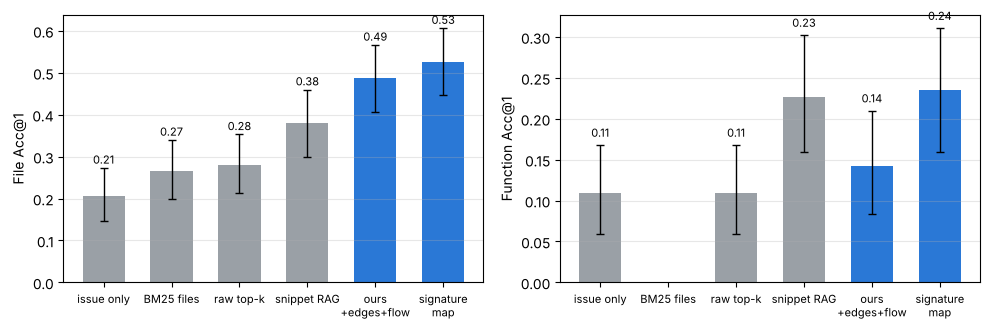

In [8]:
df = pd.read_json(f"{R}/run_v3.jsonl", lines=True)
for c in ("file_acc1", "func_acc1"): df[c] = df[c].astype(float)
from bench.metrics import bootstrap_ci
meth = [("issue_only", "issue only"), ("bm25_files", "BM25 files"), ("raw_topk", "raw top-k"), ("snippet_rag", "snippet RAG"), ("ours", "ours\n+edges+flow"), ("repomap_sig", "signature\nmap")]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a, col, ttl in zip(ax, ("file_acc1", "func_acc1"), ("File Acc@1", "Function Acc@1")):
    for i, (m, lab) in enumerate(meth):
        if m == "bm25_files" and col == "func_acc1": continue
        mu, lo, hi = bootstrap_ci(df[df.method == m][col].dropna())
        a.bar(i, mu, color="#2a78d6" if m in ("ours", "repomap_sig") else "#9aa0a6", width=.62)
        a.errorbar(i, mu, yerr=[[mu - lo], [hi - mu]], color="k", lw=1, capsize=3); a.text(i, hi + .01, f"{mu:.2f}", ha="center", fontsize=8)
    a.set_xticks(range(len(meth))); a.set_xticklabels([l for _, l in meth], fontsize=8); a.set_ylabel(ttl); a.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

**Reading it.** The signature map beats snippet RAG and raw files on finding the file (paired differences -0.147 and -0.247, Holm p = 0.004 and < 0.001). It does not beat snippet RAG on the function (0.235 vs 0.227). The richer `ours` variant is not better than plain signatures: -0.040 on file (not significant), -0.092 on function (Holm p = 0.002).

## 5. Ablations (first 60 test issues)

In [9]:
print("=== edges / control flow / ranker, reference = signatures only ==="); report("repomap_sig", "repomap_sig,sig_edges,sig_control,ours,abl_old_ranker")
print("\n=== format, file order, two-stage, reference = ours ==="); report("ours", "ours,abl_json,abl_alpha_order,abl_shuffle_order,ours_2stage")

=== edges / control flow / ranker, reference = signatures only ===


[restricted to 60 instances present for all 5 methods]
        method  n           file_acc1           file_acc3           func_acc1  ctx_tok  prompt_tok  prefill_p50  e2e_p50_s  e2e_p95_s  tok_per_hit
abl_old_ranker 60 0.333 [0.217,0.450] 0.483 [0.350,0.617] 0.062 [0.000,0.146]     2034        2612         2838      17.76      32.93         7836
          ours 60 0.417 [0.300,0.550] 0.617 [0.500,0.733] 0.042 [0.000,0.104]     2034        2612         3184      18.59      34.98         6268
   repomap_sig 60 0.500 [0.367,0.633] 0.650 [0.533,0.767] 0.188 [0.083,0.312]     2036        2614         3106      18.37      34.94         5228
   sig_control 60 0.533 [0.400,0.667] 0.683 [0.567,0.800] 0.208 [0.104,0.333]     2036        2614         3277      19.48      32.74         4901
     sig_edges 60 0.467 [0.333,0.600] 0.667 [0.550,0.783] 0.125 [0.042,0.229]     2036        2614         2989      18.35      32.49         5601

Paired comparisons vs repomap_sig (difference, 95% CI, raw p, 

[restricted to 60 instances present for all 5 methods]
           method  n           file_acc1           file_acc3           func_acc1  ctx_tok  prompt_tok  prefill_p50  e2e_p50_s  e2e_p95_s  tok_per_hit
  abl_alpha_order 60 0.550 [0.417,0.683] 0.650 [0.533,0.767] 0.125 [0.042,0.229]     2034        2605         3151      18.56      35.96         4736
         abl_json 60 0.400 [0.283,0.533] 0.633 [0.517,0.750] 0.062 [0.000,0.146]     2033        2597         3287      19.73      36.17         6493
abl_shuffle_order 60 0.467 [0.333,0.600] 0.650 [0.533,0.767] 0.146 [0.062,0.250]     2034        2605         2967      17.80      35.96         5581
             ours 60 0.417 [0.300,0.550] 0.617 [0.500,0.733] 0.042 [0.000,0.104]     2034        2612         3184      18.59      34.98         6268
      ours_2stage 60 0.467 [0.350,0.600] 0.617 [0.500,0.733] 0.229 [0.125,0.354]     2718        3803         4098      23.14      42.21         8148

Paired comparisons vs ours (difference, 95% 

Only two differences survive the multiple-comparison correction: `ours` is worse than signatures on function accuracy, and the two-stage prompt is better than one-stage `ours` on function accuracy (0.042 to 0.229, at +1191 prompt tokens and about 4.5 s). The rest is within noise at n = 60.

## 6. Budget sweep (first 60 test issues)

     method  budget  n  file_acc1  func_acc1  prompt_tok  e2e_p95_s
repomap_sig     512 60      0.533      0.167    1080.600     34.320
repomap_sig    1024 60      0.550      0.188    1588.217     33.919
repomap_sig    2048 60      0.500      0.188    2614.233     34.935
repomap_sig    4096 60      0.517      0.188    4662.200     42.000
       ours     512 60      0.467      0.125    1079.033     34.086
       ours    1024 60      0.483      0.146    1590.850     33.104
       ours    2048 60      0.417      0.042    2611.583     34.979
       ours    4096 60      0.583      0.167    4663.250     40.685
snippet_rag     512 60      0.383      0.208    1043.117     34.961
snippet_rag    1024 60      0.433      0.229    1553.483     33.416
snippet_rag    2048 60      0.433      0.271    2577.400     33.953
snippet_rag    4096 60      0.500      0.312    4597.650     40.489


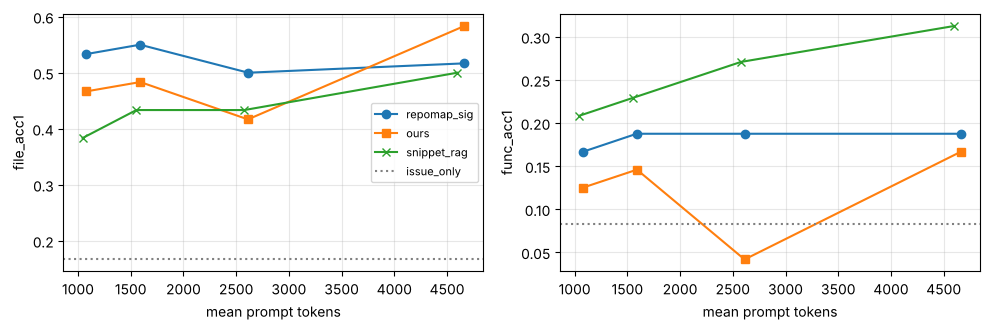

In [10]:
sw = pd.read_csv(f"{R}/sweep.csv"); print(sw.round(3).to_string(index=False))
io = df[(df.method == "issue_only") & df.instance_id.isin(list(dict.fromkeys(df[df.method == "ours"].instance_id))[:60])]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a, col in zip(ax, ("file_acc1", "func_acc1")):
    for m, mk in (("repomap_sig", "o"), ("ours", "s"), ("snippet_rag", "x")):
        g = sw[sw.method == m]; a.plot(g.prompt_tok, g[col], marker=mk, label=m)
    a.axhline(io[col].mean(), color="gray", ls=":", label="issue_only"); a.set_xlabel("mean prompt tokens"); a.set_ylabel(col); a.grid(alpha=.3)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

More map does not buy more file accuracy for `repomap_sig` (flat from ~1.1k to ~4.7k prompt tokens). Snippet RAG keeps improving and is the best at function level at every budget.

## 7. Why does the gold file go missing? Ranking miss vs model miss

In [11]:
ids = list(dict.fromkeys(df[df.method == "ours"].instance_id))[:60]
print("From the T4 run, first 60 test issues (coverage computed on the same prompts):")
print("ours       : gold file in prompt 47/60 (78%) | correct when present 0.53 | when absent 0.00 (0/13)")
print("repomap_sig: gold file in prompt 48/60 (80%) | correct when present 0.62 | when absent 0.00 (0/12)")
print("\nFile Acc@1 by repository (test, n=150):")
print(df[df.method.isin(["issue_only", "snippet_rag", "repomap_sig", "ours"])].pivot_table(index="repo", columns="method", values="file_acc1", aggfunc=["mean"]).round(2).droplevel(0, axis=1).join(
    df[df.method == "ours"].groupby("repo").size().rename("n")))

From the T4 run, first 60 test issues (coverage computed on the same prompts):
ours       : gold file in prompt 47/60 (78%) | correct when present 0.53 | when absent 0.00 (0/13)
repomap_sig: gold file in prompt 48/60 (80%) | correct when present 0.62 | when absent 0.00 (0/12)

File Acc@1 by repository (test, n=150):
                           issue_only  ours  repomap_sig  snippet_rag   n
repo                                                                     
astropy/astropy                  0.50  0.75         0.75         0.75   4
django/django                    0.29  0.58         0.64         0.49  59
matplotlib/matplotlib            0.00  0.33         0.33         0.33   9
mwaskom/seaborn                  0.50  0.50         0.50         0.00   2
pallets/flask                    0.00  0.00         0.00         0.00   1
psf/requests                     0.00  0.50         0.50         0.50   2
pydata/xarray                    0.00  0.33         0.67         0.33   3
pylint-dev/pylin

The two failure kinds are both real: about 20% of issues never show the gold file to the model, and when it is shown the model still picks a neighbour (e.g. `django/db/models/query.py` instead of `.../sql/query.py`) 38-47% of the time. Small repositories have only 1-4 test issues, so their rows are not informative.

## 8. Memory and prefill on a T4
The checkpoint is bigger than "4-bit" implies: 9081 MiB resident, of which 5376 MiB are per-layer embeddings and 1280 MiB the token embedding, both kept in bf16. Only the 2146 MiB of compute weights are quantized. The model has 35 sliding-window layers (window 512), 7 full-attention layers, 2 KV heads, and 18 layers that share KV, so its KV cache is small.

   T  peak_mb  kv_act_mb  prefill_ms  analytic_kv_mib  kv_share_of_growth  growth_vs_prev
 256     9182         93         304             14.0               0.151             NaN
 512     9226        137         511             28.0               0.204            1.47
1024     9377        288        1009             36.0               0.125            2.10
2048     9816        727        2430             52.0               0.072            2.52
3072    10409       1320        4631             68.0               0.052            1.82
4096    11158       2069        9012             84.0               0.041            1.57
6144    13115       4026       13161            116.0               0.029            1.95


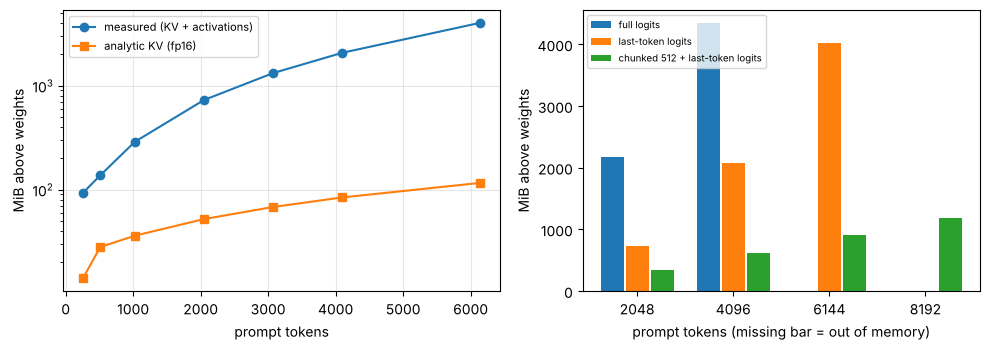

In [12]:
mem = pd.read_csv(f"{R}/memory.csv"); print(mem.to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1.1, 1]})
ax[0].plot(mem["T"], mem.kv_act_mb, "o-", label="measured (KV + activations)"); ax[0].plot(mem["T"], mem.analytic_kv_mib, "s-", label="analytic KV (fp16)")
ax[0].set_yscale("log"); ax[0].set_xlabel("prompt tokens"); ax[0].set_ylabel("MiB above weights"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
probe = {2048: (2172, 728, 347), 4096: (4340, 2069, 624), 6144: (np.nan, 4026, 909), 8192: (np.nan, np.nan, 1191)}  # full logits / last-token logits / chunked(512)+last-token
x = np.arange(4); w = .26
for j, lab in enumerate(["full logits", "last-token logits", "chunked 512 + last-token logits"]):
    ax[1].bar(x + (j - 1) * w, [v[j] for v in probe.values()], w * .92, label=lab)
ax[1].set_xticks(x); ax[1].set_xticklabels(list(probe)); ax[1].set_xlabel("prompt tokens (missing bar = out of memory)"); ax[1].set_ylabel("MiB above weights"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

The analytic KV cache is 3% of the measured growth at 6144 tokens (at most ~20% at any length). The vocabulary of 262,144 makes logits for every prompt position the biggest single allocation; asking for the last position only, and prefilling in 512-token chunks, is what lets an 8k prompt run at all on a T4 (1191 MiB above weights, 15.4 s). The probe code is in `notebooks/benchmark_v3.ipynb`, section 8.

## 9. Compression ratio

Over 10 test issues (run on the T4 machine, repositories cloned there): the whole-repo symbol graph is on average **4.8x** smaller than the Python source (estimated at 3.5 characters per token); after ranking and budgeting to 2k tokens the ratio is about **2300x** (range 500 to 4200). The first number is what AST compression itself buys; the second is mostly selection.

## 10. Using it in a project
```python
from astgraph import RepoIndex
idx = RepoIndex.from_path("path/to/repo")
ctx = idx.context(issue_text, budget=2048)      # 1. prompt layer: prepend ctx.text to the prompt
```
```python
from astgraph.tools import ToolKit, TOOL_SPECS   # 2. tools: give TOOL_SPECS to the model, run ToolKit(idx).dispatch(name, args)
```
Mode 1 is what the numbers above measure. Mode 2 (and the MCP server in the repo) is built and unit-tested but **not yet benchmarked with Gemma 4**; the repository's `docs/integration.md` lays out the experiment.

## 11. Limits
One model, 4-bit, greedy, one run. Localization only, not patch generation. Python only. Name-based call edges. The signature-map baseline is our own approximation of an Aider-style map. Intervals are wide at n = 150 (about +-0.08) and n = 60 (about +-0.12); only differences with a small Holm-adjusted p are claimed as results.